In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

##### =====================================================
# 1. LOAD DATASETS
##### =====================================================

In [2]:
campaigns = pd.read_csv(r"D:\DS\JC-Uttam-956e\codebasic final 30.06.26\DS\Virtual Internship - 1\2.21\my_working\datasets\dim_campaigns.csv")
products = pd.read_csv(r"D:\DS\JC-Uttam-956e\codebasic final 30.06.26\DS\Virtual Internship - 1\2.21\my_working\datasets\dim_products.csv")
stores = pd.read_csv(r"D:\DS\JC-Uttam-956e\codebasic final 30.06.26\DS\Virtual Internship - 1\2.21\my_working\datasets\dim_stores.csv")
events = pd.read_csv(r"D:\DS\JC-Uttam-956e\codebasic final 30.06.26\DS\Virtual Internship - 1\2.21\my_working\datasets\fact_events.csv")

##### =====================================================
## Q1. Visualize the number of stores in each city. Identify the city with the most stores and explain the distribution of stores across other cities. How does the number of stores in Bengaluru compare with those in Hyderabad and Chennai? (Hint: Use a bar chart to visualize the number of stores by city
##### =====================================================

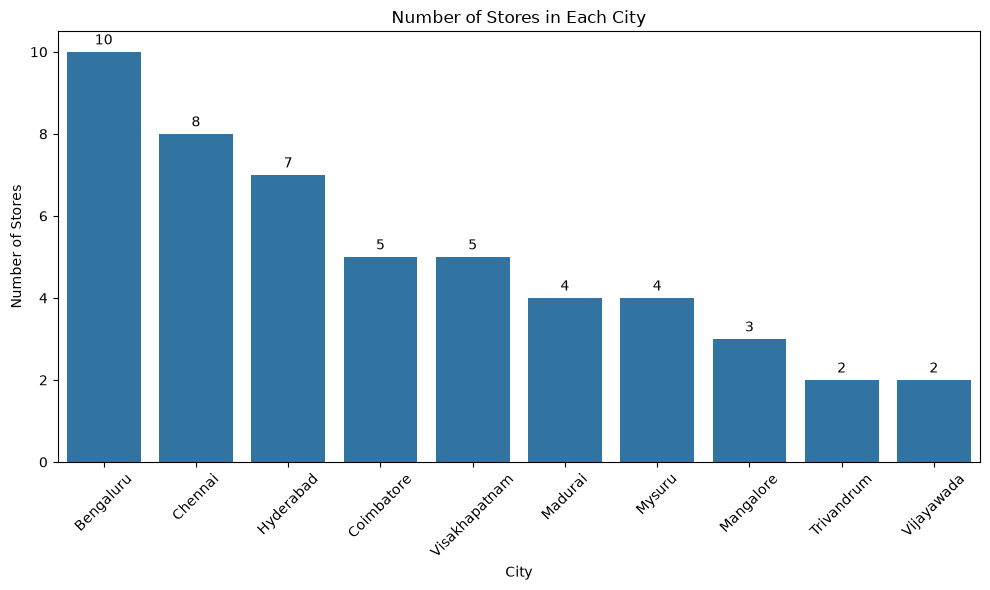

In [3]:
# Count the number of stores in each city
city_store_count = (
    stores.groupby("city")['store_id'].nunique()
    .sort_values(ascending=False)
)

# Create bar chart
plt.figure(figsize=(10,6))

ax = sns.barplot(
    x=city_store_count.index,
    y=city_store_count.values
)

# Add values on top of each bar
ax.bar_label(ax.containers[0], padding=3)

plt.title('Number of Stores in Each City')
plt.xlabel('City')
plt.ylabel('Number of Stores')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

##### =====================================================
## Q2. Analyze the total quantity sold after promotion for the Sankranti campaign across different product categories. What percentage does each category contribute to the overall sales, and what insights can be drawn from these contributions? (Hint: Use a pie chart to visualize percentage contribution of each category to the overall sales)
##### =====================================================

                   total_quantity_sold  contribution_%
category                                              
Grocery & Staples               177724           70.51
Home Appliances                  35610           14.13
Home Care                        16894            6.70
Combo1                           12411            4.92
Personal Care                     9430            3.74


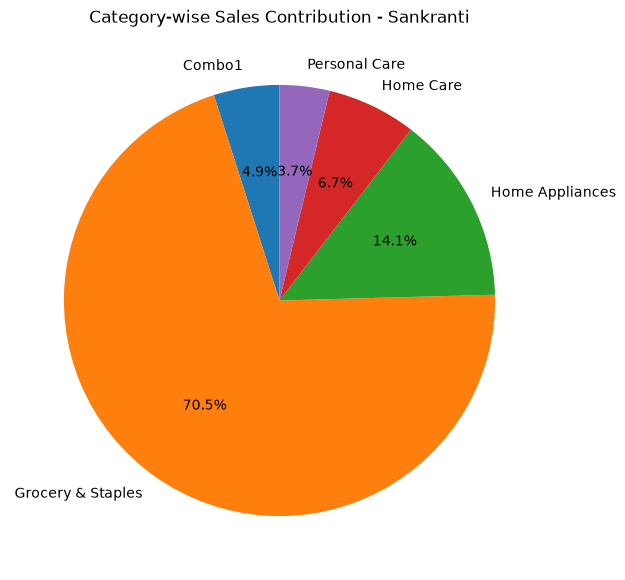

In [4]:
# Filter Sankranti campaign
sankranti_id = campaigns.loc[
    campaigns['campaign_name'].str.contains('Sankranti', case=False, na=False),
    'campaign_id'
].iloc[0]

sankranti_df = events[
    events['campaign_id'] == sankranti_id
]

# Merge product category information
sankranti_df = sankranti_df.merge(
    products[['product_code', 'category']],
    on='product_code',
    how='left'
)

# Calculate total quantity sold after promotion by category
category_sales = sankranti_df.groupby('category')[
    'quantity_sold(after_promo)'
].sum()

# Calculate percentage contribution
category_contribution = (
    category_sales / category_sales.sum()
) * 100

# Display results
result = category_sales.to_frame(name='total_quantity_sold')
result['contribution_%'] = category_contribution

print(result.sort_values('contribution_%', ascending=False).round(2))

# Plot pie chart
plt.figure(figsize=(9, 7))

plt.pie(
    category_sales,
    labels=category_sales.index,
    autopct='%1.1f%%',
    startangle=90
)

plt.title('Category-wise Sales Contribution - Sankranti')
plt.show()



##### =====================================================
## Q3. Examine the correlation between base price (after the promotion) and sales quantities (after the promotion). What insights can be drawn regarding the relationship between base price and sales quantities after the promotion? (Hint: Use heatmap to get the correlation)
##### =====================================================

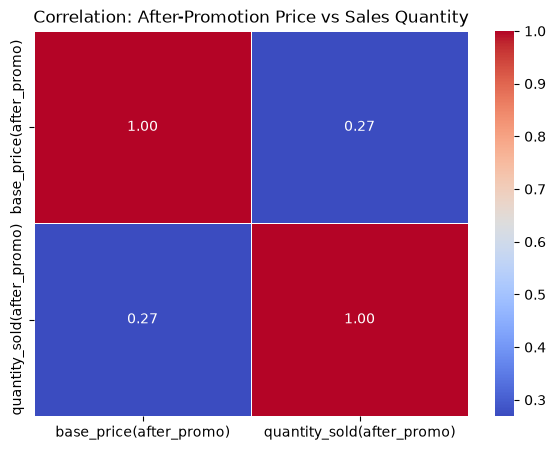

In [5]:
# Select the required columns
correlation = events[
    ['base_price(after_promo)','quantity_sold(after_promo)']
].corr()

# Display correlation heatmap
plt.figure(figsize=(7,5))

sns.heatmap(
    correlation,
    annot = True,
    cmap = 'coolwarm',
    fmt ='.2f',
    linewidths=0.5
)

plt.title('Correlation: After-Promotion Price vs Sales Quantity')
plt.show()

##### =====================================================
## Q4. Analyze the distribution of quantity sold before the promotion for each product category (Grocery & Staples, Home Care, Personal Care, Home Appliances, etc.). What patterns or trends do you observe across these categories, and how could these insights inform future promotional strategies? (Hint: Use individual histograms to visualize the distribution)
##### =====================================================

Creating histogram for: Grocery & Staples


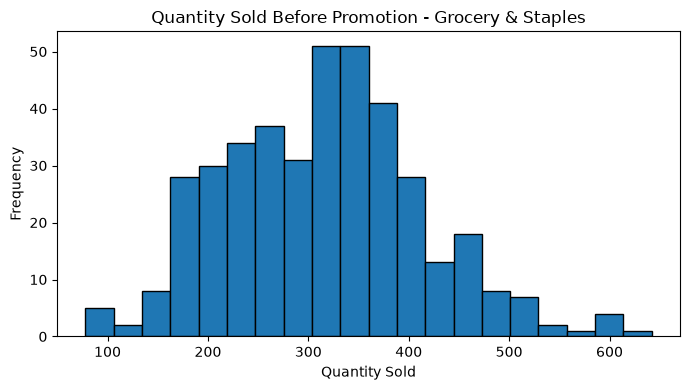

Creating histogram for: Home Care


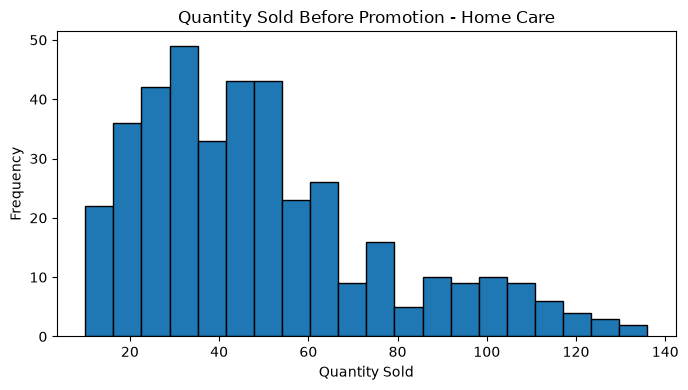

Creating histogram for: Combo1


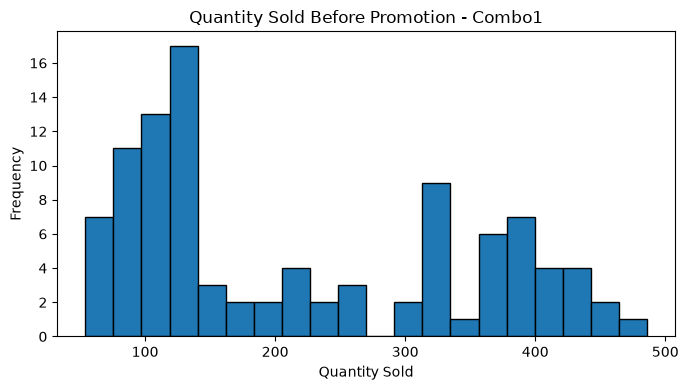

Creating histogram for: Home Appliances


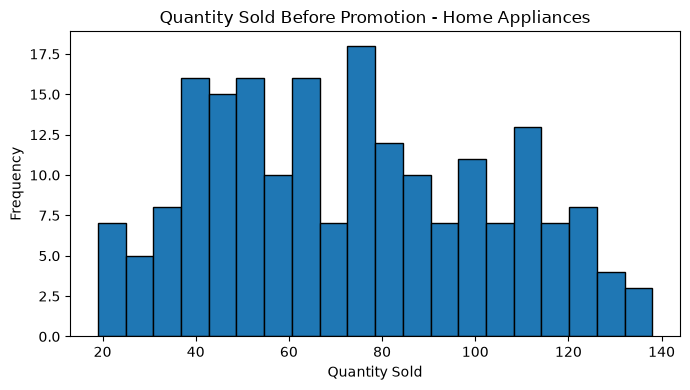

Creating histogram for: Personal Care


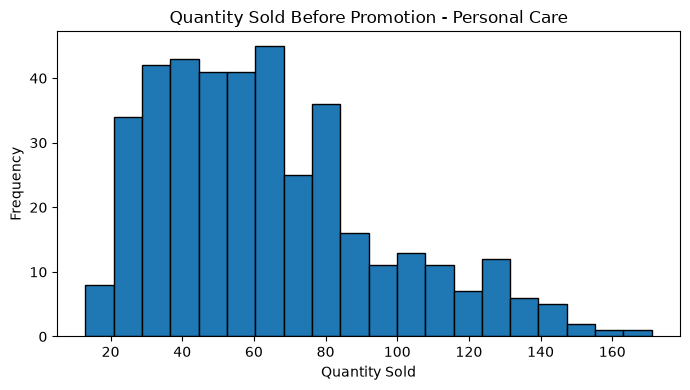

In [15]:
import matplotlib.pyplot as plt

categories = df["category"].dropna().unique()

for category in categories:

    category_data = df.loc[
        df["category"] == category,
        "quantity_sold(before_promo)"
    ].dropna()

    print(f"Creating histogram for: {category}")

    plt.figure(figsize=(7, 4))

    plt.hist(category_data, bins=20, edgecolor="black")

    plt.title(f"Quantity Sold Before Promotion - {category}")
    plt.xlabel("Quantity Sold")
    plt.ylabel("Frequency")

    plt.tight_layout()
    plt.show()

##### =====================================================
## Q5. Analyze the incremental sold units percentage (ISU%) across various cities. Identify the city with the highest ISU% after the promotion and the city with the smallest change. What trends can be observed about the effectiveness of promotions in driving sales across these cities? (Hint: Use a line chart to visualize the ISU% comparison across cities)
##### =====================================================

,quantity_sold(before_promo),quantity_sold(after_promo),ISU%
city,,,
Bengaluru,48972.0,105141,114.696153
Chennai,39183.0,83273,112.523288
Coimbatore,18200.0,38900,113.736264
Hyderabad,34335.0,69399,102.123198
Madurai,14086.0,31169,121.276445
Mangalore,7454.0,14929,100.281728
Mysuru,18202.0,37470,105.856499
Trivandrum,4884.0,10170,108.230958
Vijayawada,5297.0,11106,109.665849


City with highest ISU%: Madurai
City with smallest ISU%: Visakhapatnam


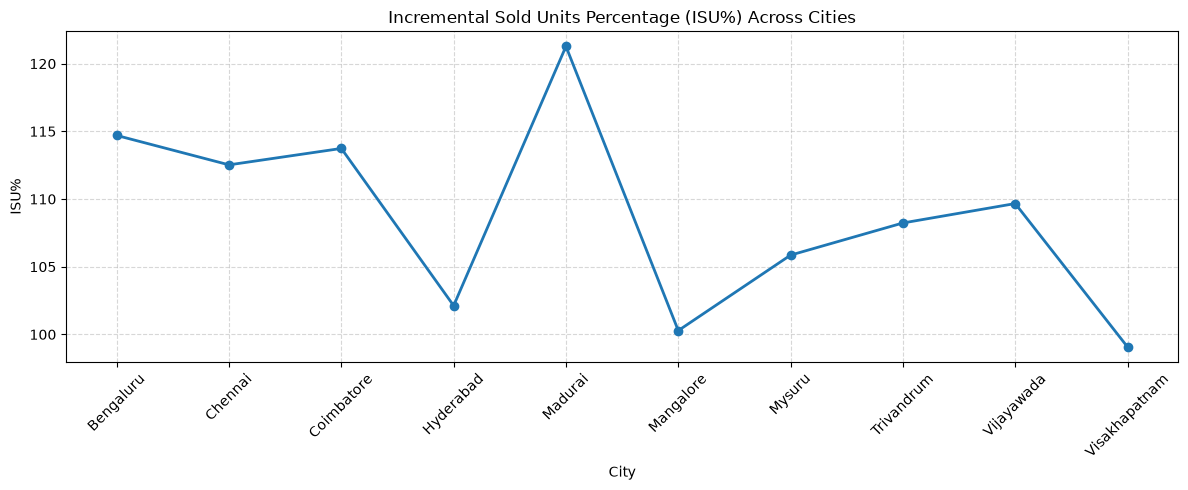

In [19]:
# 1. Merge fact_events with dim_stores
df = events.merge(
    stores[['store_id','city']],
    on = 'store_id',
    how = 'left'
)

# 2. Calculate city-wise total quantities
city_sales = df.groupby('city')[
    ['quantity_sold(before_promo)','quantity_sold(after_promo)']
].sum()

# 3. Calculate ISU%
city_sales['ISU%'] = (
(city_sales['quantity_sold(after_promo)']-
 city_sales['quantity_sold(before_promo)'])
/city_sales['quantity_sold(before_promo)'])*100

# 4. Display results
display(city_sales)

# 5. Identify highest and smallest ISU%
print("City with highest ISU%:", city_sales["ISU%"].idxmax())
print("City with smallest ISU%:", city_sales["ISU%"].idxmin())

# 6. Create line chart
plt.figure(figsize=(12, 5))

plt.plot(
    city_sales.index,
    city_sales["ISU%"],
    marker="o",
    linewidth=2
)

plt.title("Incremental Sold Units Percentage (ISU%) Across Cities")
plt.xlabel("City")
plt.ylabel("ISU%")
plt.xticks(rotation=45)
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()


##### =====================================================
## Q6. Analyze the relationship between incremental revenue and incremental sold units for different promotion types in Hyderabad. Which promotion type led to the highest incremental sold units, and which one generated the highest incremental revenue? What insights can you draw from the balance between the two metrics for this city? (Hint: Use a scatter plot to analyze the relationship)
##### =====================================================

,revenue_before,revenue_after,units_before,units_after,IR%,ISU%
promo_type,,,,,,
25% OFF,1547135.0,1009192,7288.0,6348,-34.770269,-12.897914
33% OFF,6015872.0,5836633,10404.0,15104,-2.979435,45.174933
50% OFF,360534.0,245212,3592.0,4883,-31.986442,35.940980
500 Cashback,10476000.0,23342500,3492.0,9337,122.818824,167.382589
BOGOF,4293700.0,7476120,9559.0,33727,74.118359,252.829794


Highest ISU%: BOGOF
Highest IR%: 500 Cashback


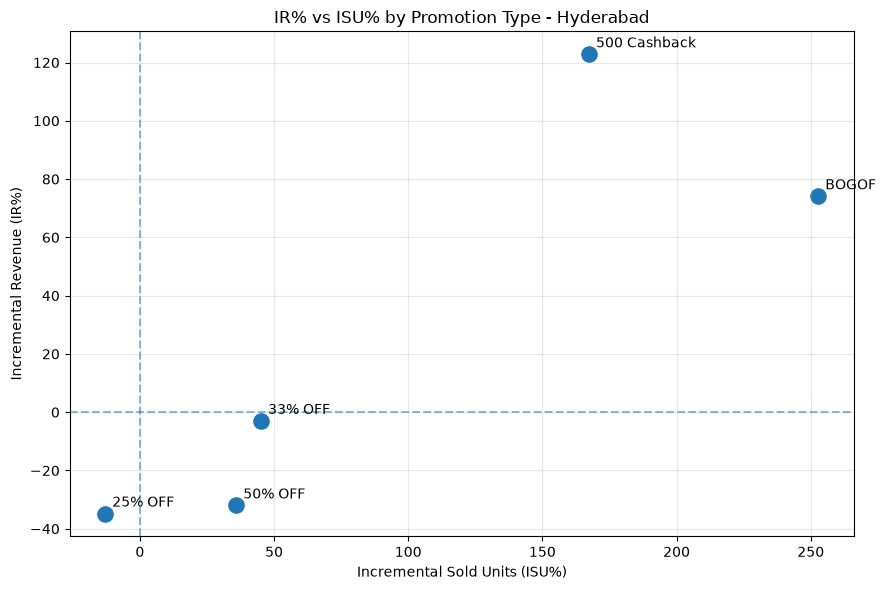

In [22]:
# 1. Merge fact_events with dim_stores
df = events.merge(
    stores[['store_id','city']],
    on = 'store_id',
    how = 'left'
)

# 2. Filter Hyderabad city
df = df[df['city']=='Hyderabad'].copy()

# 3. Calculate revenue before and after promotion
df["revenue_before"] = (
    df["base_price(before_promo)"] *
    df["quantity_sold(before_promo)"]
)

df["revenue_after"] = (
    df["base_price(after_promo)"] *
    df["quantity_sold(after_promo)"]
)

# 4. Group by promotion type
result = df.groupby("promo_type").agg(
    revenue_before=("revenue_before", "sum"),
    revenue_after=("revenue_after", "sum"),
    units_before=("quantity_sold(before_promo)", "sum"),
    units_after=("quantity_sold(after_promo)", "sum")
)

# 5. Calculate IR% and ISU%
result["IR%"] = (
    (result["revenue_after"] - result["revenue_before"])
    / result["revenue_before"]
) * 100

result["ISU%"] = (
    (result["units_after"] - result["units_before"])
    / result["units_before"]
) * 100

# 6. Display results
display(result)

# 7. Identify highest IR% and ISU%
print("Highest ISU%:", result["ISU%"].idxmax())
print("Highest IR%:", result["IR%"].idxmax())

# 8. Create scatter plot
plt.figure(figsize=(9, 6))

plt.scatter(
    result["ISU%"],
    result["IR%"],
    s=120
)

# Add promotion type labels
for promo, row in result.iterrows():
    plt.annotate(
        promo,
        (row["ISU%"], row["IR%"]),
        xytext=(5, 5),
        textcoords="offset points"
    )

plt.title("IR% vs ISU% by Promotion Type - Hyderabad")
plt.xlabel("Incremental Sold Units (ISU%)")
plt.ylabel("Incremental Revenue (IR%)")
plt.axhline(0, linestyle="--", alpha=0.5)
plt.axvline(0, linestyle="--", alpha=0.5)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

##### =====================================================
## Q7. Analyze the revenue before and after promotions across different product categories in Bengaluru. What trends can be identified in the performance of each category, and how did promotions impact overall revenue in the city? (Hint: Use a vertical bar chart to compare the revenue before and after promotions)
##### =====================================================

,revenue_before,revenue_after,revenue_increase
category,,,
Combo1,15777000.0,38125000,22348000.0
Grocery & Staples,12262460.0,13861259,1598799.0
Home Appliances,2188810.0,4122680,1933870.0
Home Care,2104460.0,3180020,1075560.0
Personal Care,576321.0,389629,-186692.0


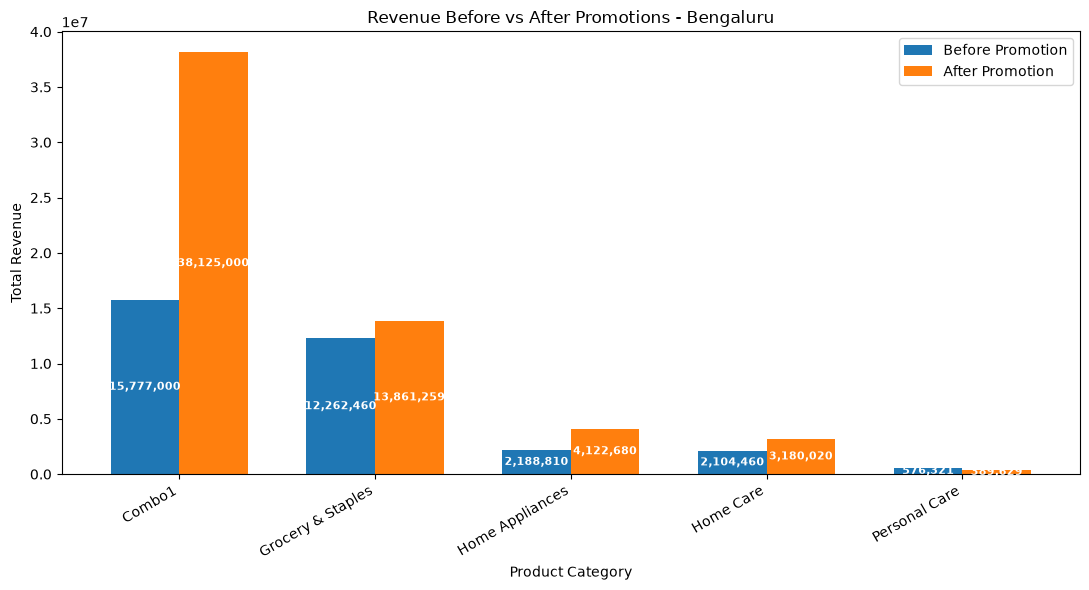

Total Revenue Before Promotion: 32909051.0
Total Revenue After Promotion: 59678588
Overall Revenue Increase: 26769537.0
Overall Revenue Growth (%): 81.34


In [23]:
# 1. Merge fact_events with dim_stores and dim_products
df = events.merge(
    stores[["store_id", "city"]],
    on="store_id",
    how="left"
).merge(
    products[["product_code", "category"]],
    on="product_code",
    how="left"
)

# 2. Filter Bengaluru city
df = df[df["city"] == "Bengaluru"].copy()

# 3. Calculate revenue before and after promotion
df["revenue_before"] = (
    df["base_price(before_promo)"] *
    df["quantity_sold(before_promo)"]
)

df["revenue_after"] = (
    df["base_price(after_promo)"] *
    df["quantity_sold(after_promo)"]
)

# 4. Calculate category-wise revenue
result = df.groupby("category")[
    ["revenue_before", "revenue_after"]
].sum()

# 5. Calculate revenue increase
result["revenue_increase"] = (
    result["revenue_after"] - result["revenue_before"]
)

display(result)

# 6. Create vertical bar chart
ax = result[
    ["revenue_before", "revenue_after"]
].plot(
    kind="bar",
    figsize=(11, 6),
    width=0.7
)

# 7. Display values inside bars
for container in ax.containers:
    labels = [f"{bar.get_height():,.0f}" for bar in container]
    ax.bar_label(
        container,
        labels=labels,
        label_type="center",
        color="white",
        fontweight="bold",
        fontsize=8
    )

plt.title("Revenue Before vs After Promotions - Bengaluru")
plt.xlabel("Product Category")
plt.ylabel("Total Revenue")
plt.xticks(rotation=30, ha="right")
plt.legend(["Before Promotion", "After Promotion"])
plt.tight_layout()
plt.show()

# 8. Calculate overall revenue impact
total_before = result["revenue_before"].sum()
total_after = result["revenue_after"].sum()

print("Total Revenue Before Promotion:", total_before)
print("Total Revenue After Promotion:", total_after)
print("Overall Revenue Increase:", total_after - total_before)

print(
    "Overall Revenue Growth (%):",
    round(((total_after - total_before) / total_before) * 100, 2)
)